1. Iuhufheu hfz


In [1]:
# a rajouter : installation dependency 'odfpy'.
#pip install odfpy

On commence par vérifier les données, puis on compare les groupes. Les textes restent courts et les bases de calcul sont affichées.

In [2]:
#mettre dans requirements.txt
import pandas as pd
import os 
import numpy as np
import matplotlib.pyplot as plt

In [3]:
filepath = "../hadopi-2020-musique-data.ods"
df = pd.read_excel(filepath)


In [4]:
df.shape

(2200, 261)

In [5]:
print(df.columns.tolist())

['SEXE', 'QSEXE', 'RAGE2', 'RAGE3', 'XRAGE', 'AGGLOIFOP2', 'REG', 'REG2', 'REG3', 'REG13', 'REG13C', 'PI4', 'STATUT', 'PCF4', 'FOYER', 'ENF', 'RS1', 'QRS1', 'Q1_1', 'Q1_2', 'Q1_3', 'Q1_4', 'Q1_5', 'Q1_6', 'Q1_7', 'Q1_8', 'Q1_9', 'Q1_10', 'Q1_11', 'Q2_r1', 'Q2_r2', 'Q2_r3', 'Q2_r4', 'Q2_r5', 'Q2_r6', 'Q2_r7', 'Q2_r8', 'Q2_r9', 'Q2_r10', 'Q2_r11', 'Q3', 'Q4', 'Q5_1', 'Q5_2', 'Q5_3', 'Q5_4', 'Q5_5', 'Q5_6', 'Q5_7', 'Q5_8', 'Q5_9', 'Q5_10', 'Q5_11', 'Q5_12', 'Q5_13', 'Q6_r1', 'Q6_r2', 'Q6_r3', 'Q6_r4', 'Q6_r5', 'Q6_r6', 'Q6_r7', 'Q7', 'Q7bis', 'Q8_1', 'Q8_2', 'Q8_3', 'Q8_4', 'Q8_5', 'Q8_6', 'Q16_1', 'Q16_2', 'Q16_3', 'Q16_4', 'Q16_5', 'Q16_6', 'Q16_7', 'Q16_8', 'Q16_9', 'Q16_10', 'Q16_11', 'Q16_12', 'Q17', 'Q18_1', 'Q18_2', 'Q18_3', 'Q18_4', 'Q18_5', 'Q18_6', 'Q18_7', 'Q18_8', 'Q18_9', 'Q19_r1', 'Q19_r2', 'Q20_r1', 'Q20_r2', 'Q20_r3', 'Q20_r4', 'Q20_r5', 'Q21_r1', 'Q21_r2', 'Q21_r3', 'Q21_r4', 'ALEA', 'Q22ALEA1', 'Q22ALEA2', 'Q23_r1', 'Q23_r2', 'Q24_1', 'Q24_2', 'Q24_3', 'Q24_4', 'Q24_5', 

In [6]:
df.head(5)

,SEXE,QSEXE,RAGE2,RAGE3,XRAGE,AGGLOIFOP2,REG,REG2,REG3,REG13,...,Q60_3,Q60_4,Q60_5,Q61_r1_c1,Q61_r2_c1,Q61_r3_c1,Q61_r4_c1,DISPQUAL,sys_block_set_1,poids
0,Une femme,FEMME,De65aPlus,PlusDe49ans,Femme35ansEtPlus,MoinsDe100000Habitants,UDA7,BUDA4,PROVINCE,LanguedicRoussillonMidiP,...,#NUL!,#NUL!,#NUL!,#NUL!,Entre 1 et 49,#NUL!,#NUL!,Long,"2,3,1",1.006791
1,Une femme,FEMME,De50a64ans1,PlusDe49ans,Femme35ansEtPlus,PlusDe100000Habitants,UDA6,BUDA3,PROVINCE,PaysDeLaLoire1,...,0,0,0,150 et plus,50 et plus,#NUL!,#NUL!,Long,"3,2,1",0.695394
2,Une femme,FEMME,De15a24ans,MoinsDe35ans,FemmeMoinsDe35ans,PlusDe100000Habitants,UDA2,BUDA2,PROVINCE,NordPasDeCalaisPicardie,...,L’offre légale est plus agréable à utiliser,0,0,Entre 50 et 99,#NUL!,Entre 50 et 99,#NUL!,Long,"1,3,2",0.659261
3,Une femme,FEMME,De35a49ans1,De35a49ans2,Femme35ansEtPlus,PlusDe100000Habitants,UDA9,BUDA5,PROVINCE,ProvenceAlpesCoteDAzur,...,#NUL!,#NUL!,#NUL!,Moins de 50,Entre 1 et 49,#NUL!,#NUL!,Long,"1,2,3",1.165641
4,Un homme,HOMME,De50a64ans1,PlusDe49ans,Homme35ansEtPlus,MoinsDe100000Habitants,UDA8,BUDA5,PROVINCE,AuvergneRhoneAlpes,...,0,0,0,Moins de 50,0,#NUL!,Moins de 20,Long,"2,1,3",1.819044


In [7]:
df["SEXE"].unique()


array(['Une femme', 'Un homme'], dtype=object)

In [8]:
resume = pd.DataFrame({
    "Type": df.dtypes,
    "Valeurs manquantes": df.isna().sum(),
    "Valeurs distinctes": df.nunique()
})

display(resume)

,Type,Valeurs manquantes,Valeurs distinctes
SEXE,object,0,2
QSEXE,object,0,2
RAGE2,object,0,5
RAGE3,object,0,3
XRAGE,object,0,4
...,...,...,...
Q61_r3_c1,object,0,4
Q61_r4_c1,object,0,3
DISPQUAL,object,0,2
sys_block_set_1,object,214,6


## 2. la qualité des données


In [10]:
# Nettoyer les espaces et les codes d’absence sans transformer les zéros.
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].map(lambda x: x.strip() if isinstance(x, str) else x)
    df[col] = df[col].map(
        lambda x: np.nan if isinstance(x, str) and x in {'#NUL!', ''} else x)

audit = pd.DataFrame({
    'Type': df.dtypes.astype(str),
    'Absences (n)': df.isna().sum(),
    'Absences (%)': (100 * df.isna().mean()).round(1),
    'Modalités renseignées': df.nunique(dropna=True)
})
display(audit.sort_values('Absences (%)', ascending=False).head(15))
print('Colonnes entièrement vides :', audit.index[audit['Absences (%)'].eq(100)].tolist())
print('Lignes identiques :', df.duplicated().sum())
print('Sans identifiant individuel, une ligne identique ne prouve pas un doublon à supprimer.')


,Type,Absences (n),Absences (%),Modalités renseignées
Q2_r10,float64,2200,100.0,0
Q2_r11,float64,2200,100.0,0
Q25_10,object,2187,99.4,2
Q25_8,object,2028,92.2,2
Q55_6,object,2020,91.8,2
Q55_8,object,2020,91.8,2
Q55_7,object,2020,91.8,2
Q55_5,object,2020,91.8,2
Q55_1,object,2020,91.8,2
Q55_2,object,2020,91.8,2


Colonnes entièrement vides : ['Q2_r10', 'Q2_r11']
Lignes identiques : 6
Sans identifiant individuel, une ligne identique ne prouve pas un doublon à supprimer.


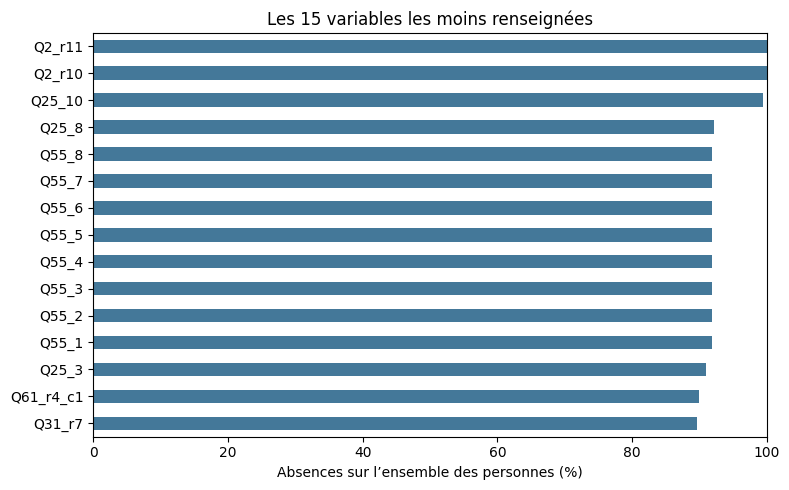

In [11]:
audit['Absences (%)'].nlargest(15).sort_values().plot.barh(
    figsize=(8, 5), color='#447899')
plt.xlabel('Absences sur l’ensemble des personnes (%)')
plt.title('Les 15 variables les moins renseignées')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


In [12]:
resume = pd.DataFrame({
    "Type": df.dtypes,
    "Valeurs manquantes": df.isna().sum(),
    "Valeurs distinctes": df.nunique()
})

display(resume)

,Type,Valeurs manquantes,Valeurs distinctes
SEXE,object,0,2
QSEXE,object,0,2
RAGE2,object,0,5
RAGE3,object,0,3
XRAGE,object,0,4
...,...,...,...
Q61_r3_c1,object,1812,3
Q61_r4_c1,object,1980,2
DISPQUAL,object,0,2
sys_block_set_1,object,214,6


In [13]:
resume["Valeurs manquantes (%)"] = (
    df.isna().mean() * 100
).round(1)

display(
    resume.sort_values("Valeurs manquantes (%)", ascending=False)
)

,Type,Valeurs manquantes,Valeurs distinctes,Valeurs manquantes (%)
Q2_r10,float64,2200,0,100.0
Q2_r11,float64,2200,0,100.0
Q25_10,object,2187,2,99.4
Q25_8,object,2028,2,92.2
Q55_6,object,2020,2,91.8
...,...,...,...,...
Q1_8,object,0,2,0.0
Q1_9,object,0,2,0.0
Q1_10,object,0,2,0.0
Q1_11,object,0,2,0.0


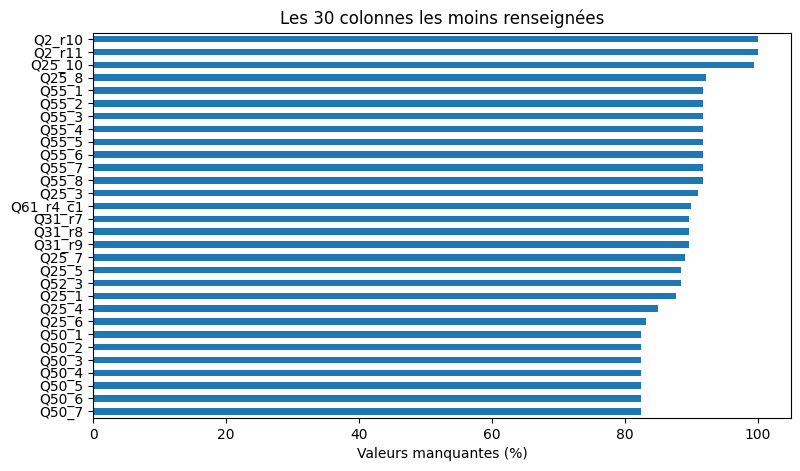

In [14]:
# Sélectionner les 15 colonnes avec le plus de valeurs manquantes
top30 = resume["Valeurs manquantes (%)"].nlargest(30)

# Créer le graphique horizontal
top30.plot.barh(figsize=(9, 5))

# Placer la colonne la moins renseignée en haut
plt.gca().invert_yaxis()

plt.xlabel("Valeurs manquantes (%)")
plt.title("Les 30 colonnes les moins renseignées")
plt.show()

In [15]:
colonnes_80 = resume[resume["Valeurs manquantes (%)"] > 80]

display(colonnes_80.sort_values("Valeurs manquantes (%)", ascending=False))

print("Nombre de colonnes concernées :", len(colonnes_80))

,Type,Valeurs manquantes,Valeurs distinctes,Valeurs manquantes (%)
Q2_r11,float64,2200,0,100.0
Q2_r10,float64,2200,0,100.0
Q25_10,object,2187,2,99.4
Q25_8,object,2028,2,92.2
Q55_7,object,2020,2,91.8
Q55_1,object,2020,2,91.8
Q55_8,object,2020,2,91.8
Q55_2,object,2020,2,91.8
Q55_3,object,2020,2,91.8
Q55_4,object,2020,2,91.8


Nombre de colonnes concernées : 54


In [16]:
valeurs = pd.DataFrame({
    "Valeurs distinctes": [
        df[colonne].dropna().unique().tolist()
        for colonne in colonnes_80.index
    ]
}, index=colonnes_80.index)

with pd.option_context("display.max_rows", None,
                       "display.max_colwidth", None):
    display(valeurs)

,Valeurs distinctes
Q2_r9,"[Uniquement de façon légale, Généralement de façon légale même s’il peut m’arriver de le faire de manière illégale, Autant de manière légale qu’illégale, Généralement de façon illégale même s’il peut m’arriver de le faire de manière légale, Uniquement de manière illégale]"
Q2_r10,[]
Q2_r11,[]
Q24_3,"[Les réseaux sociaux (Instagram, Facebook, Snapchat…), 0]"
Q25_1,"[Des services ou des applications de streaming musical (Spotify, Deezer, Apple Music, Soundcloud, Napster…), 0]"
Q25_2,"[0, Des plateformes de partage de vidéos (YouTube, Dailymotion, Tik Tok…)]"
Q25_3,"[Les réseaux sociaux (Instagram, Facebook, Snapchat…), 0]"
Q25_4,"[Des sites ou applications de radio musicales traditionnelles (Fun radio, Radio Classique, RTL2, …) ou uniquement diffu, 0]"
Q25_5,"[Les concerts / festivals, 0]"
Q25_6,"[0, Les chaînes de télévision musicales]"


In [17]:
genres = [f"Q5_{i}" for i in range(1, 14)]

for colonne in genres:
    valeurs = df[colonne].dropna()
    styles = valeurs[valeurs.astype(str) != "0"].unique()

    print(f"{colonne} : {', '.join(styles)}")

Q5_1 : Variété Française
Q5_2 : Pop / Rock
Q5_3 : Rap / Hip-Hop
Q5_4 : Classique
Q5_5 : Jazz
Q5_6 : Dance
Q5_7 : Electronique
Q5_8 : Métal
Q5_9 : R&B
Q5_10 : Soul
Q5_11 : Reggae
Q5_12 : Musiques du monde
Q5_13 : Autres genres


In [18]:
geographie = ["REG", "REG2", "REG3", "REG13", "REG13C"]

for colonne in geographie:
    print(f"\n--- {colonne} ---")
    display(df[colonne].value_counts(dropna=False))


--- REG ---


REG
UDA1    441
UDA6    292
UDA8    271
UDA7    266
UDA9    223
UDA3    199
UDA5    187
UDA4    183
UDA2    138
Name: count, dtype: int64


--- REG2 ---


REG2
BUDA2    520
BUDA5    494
BUDA3    479
BUDA1    441
BUDA4    266
Name: count, dtype: int64


--- REG3 ---


REG3
PROVINCE             1759
RegionIleDeFrance     441
Name: count, dtype: int64


--- REG13 ---


REG13
IleDeFrance1                441
AuvergneRhoneAlpes          271
AlsaceChampagneArdenneLo    220
AquitaineLimousinPoitouC    210
NordPasDeCalaisPicardie     205
LanguedicRoussillonMidiP    178
ProvenceAlpesCoteDAzur      143
PaysDeLaLoire1              139
Bretagne1                   111
Normandie                   102
BourgogneFrancheComte        95
CentreValDeLoire             85
Name: count, dtype: int64


--- REG13C ---


REG13C
IleDeFrance2              441
AuvergneRhoneAlpes1       271
AlsaceChampagneArdenn1    220
AquitaineLimousinPoit1    210
NordPasDeCalaisPicard1    205
LanguedicRoussillonMi1    178
PACACorse                 143
PaysDeLaLoire2            139
Bretagne2                 111
Normandie1                102
BourgogneFrancheComte1     95
CentreValDeLoire1          85
Name: count, dtype: int64

In [19]:
display(df[["REG13", "REG13C"]].drop_duplicates())

,REG13,REG13C
0,LanguedicRoussillonMidiP,LanguedicRoussillonMi1
1,PaysDeLaLoire1,PaysDeLaLoire2
2,NordPasDeCalaisPicardie,NordPasDeCalaisPicard1
3,ProvenceAlpesCoteDAzur,PACACorse
4,AuvergneRhoneAlpes,AuvergneRhoneAlpes1
6,AlsaceChampagneArdenneLo,AlsaceChampagneArdenn1
7,CentreValDeLoire,CentreValDeLoire1
8,AquitaineLimousinPoitouC,AquitaineLimousinPoit1
14,IleDeFrance1,IleDeFrance2
20,Bretagne1,Bretagne2


In [20]:
# Répartition des réponses pour chaque région, en pourcentage
repartition = pd.crosstab(
    df["REG13"],
    df["Q5_3"],
    normalize="index"
) * 100

display(repartition.round(1))

Q5_3,0,Rap / Hip-Hop
REG13,,
AlsaceChampagneArdenneLo,70.0,30.0
AquitaineLimousinPoitouC,75.3,24.7
AuvergneRhoneAlpes,76.8,23.2
BourgogneFrancheComte,75.0,25.0
Bretagne1,78.4,21.6
CentreValDeLoire,71.8,28.2
IleDeFrance1,68.1,31.9
LanguedicRoussillonMidiP,75.2,24.8
NordPasDeCalaisPicardie,68.6,31.4


In [21]:
regions = pd.DataFrame({
    "Effectif": df["REG13"].value_counts(),
    "Pourcentage (%)": (
        df["REG13"].value_counts(normalize=True) * 100
    ).round(1)
})

display(regions)

,Effectif,Pourcentage (%)
REG13,,
IleDeFrance1,441,20.0
AuvergneRhoneAlpes,271,12.3
AlsaceChampagneArdenneLo,220,10.0
AquitaineLimousinPoitouC,210,9.5
NordPasDeCalaisPicardie,205,9.3
LanguedicRoussillonMidiP,178,8.1
ProvenceAlpesCoteDAzur,143,6.5
PaysDeLaLoire1,139,6.3
Bretagne1,111,5.0


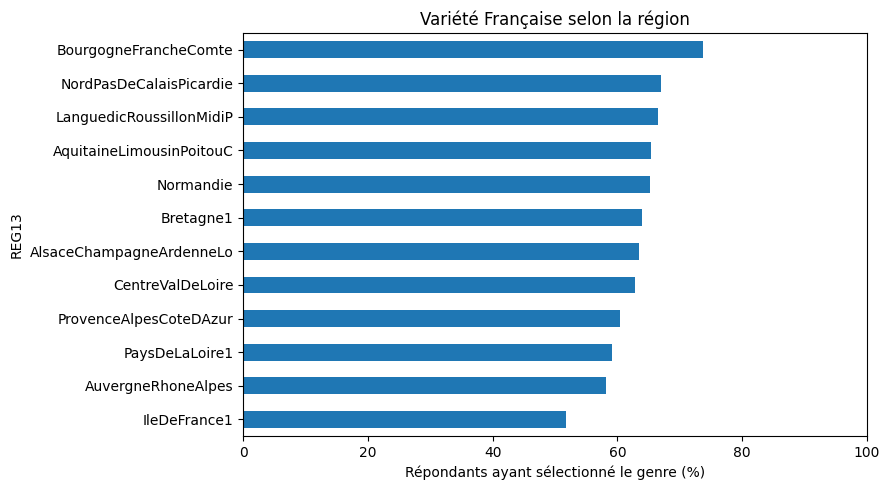

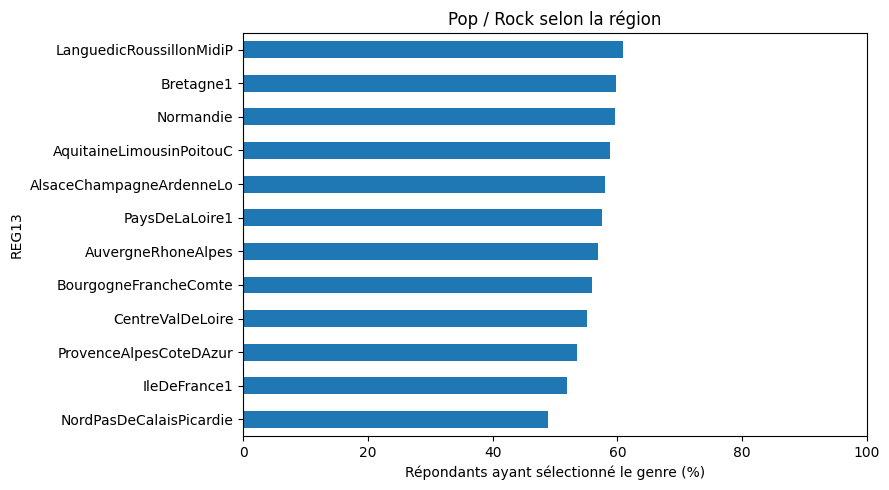

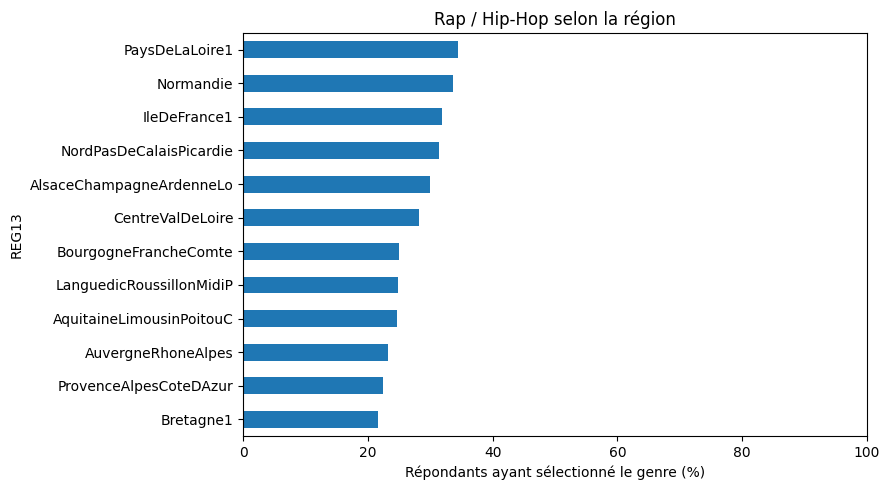

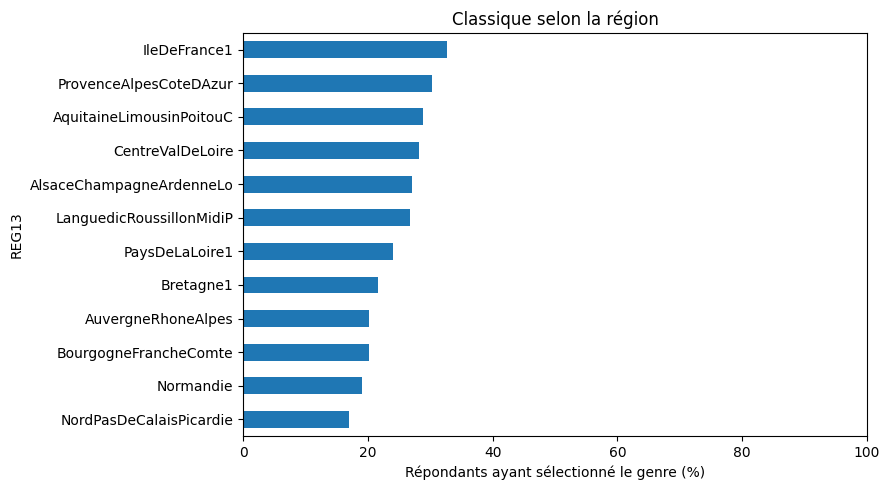

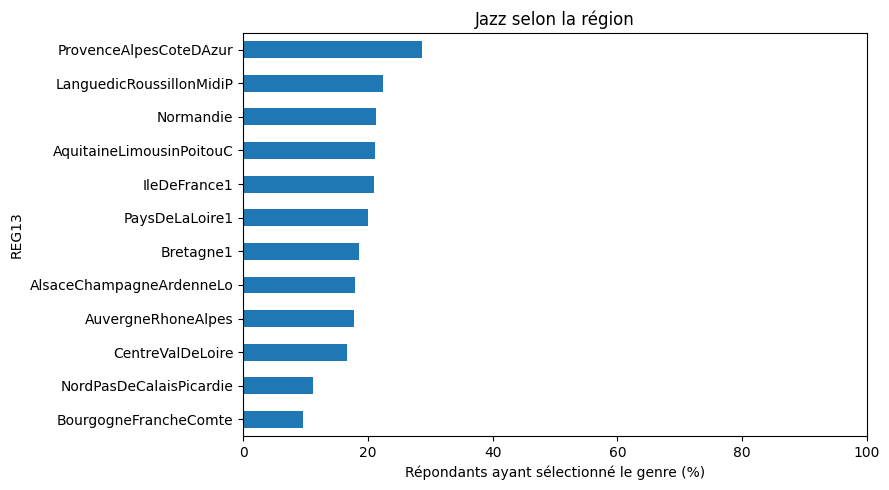

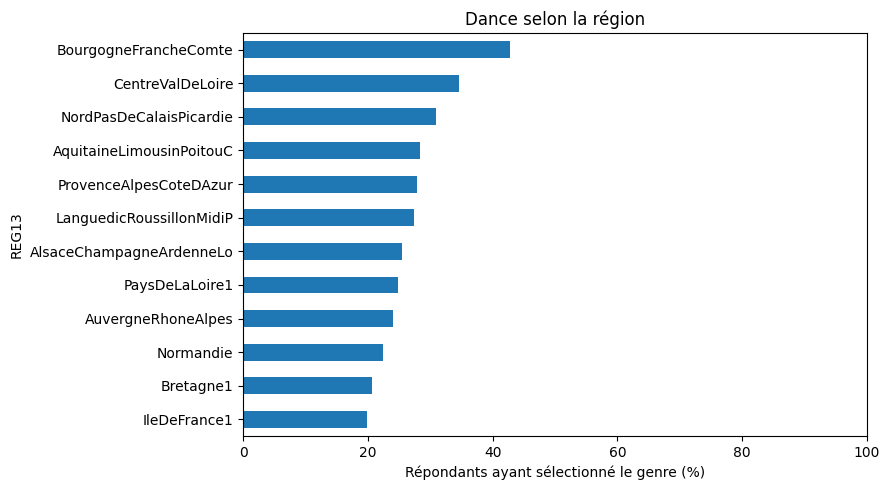

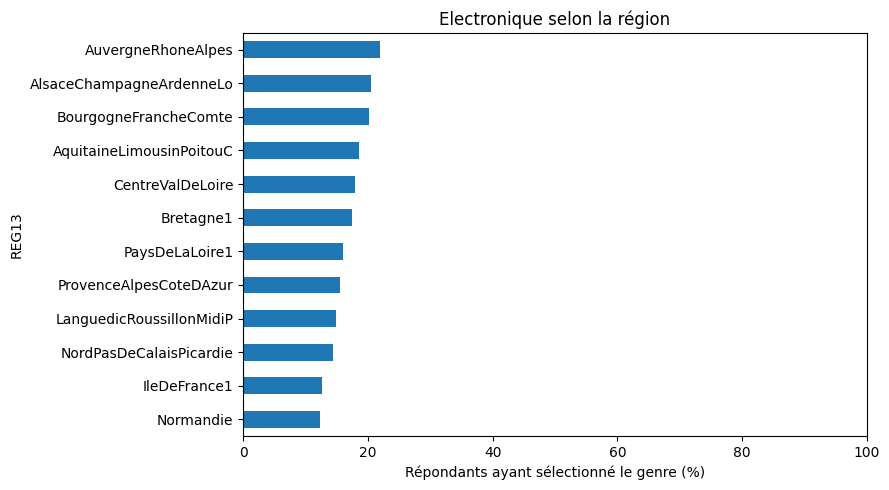

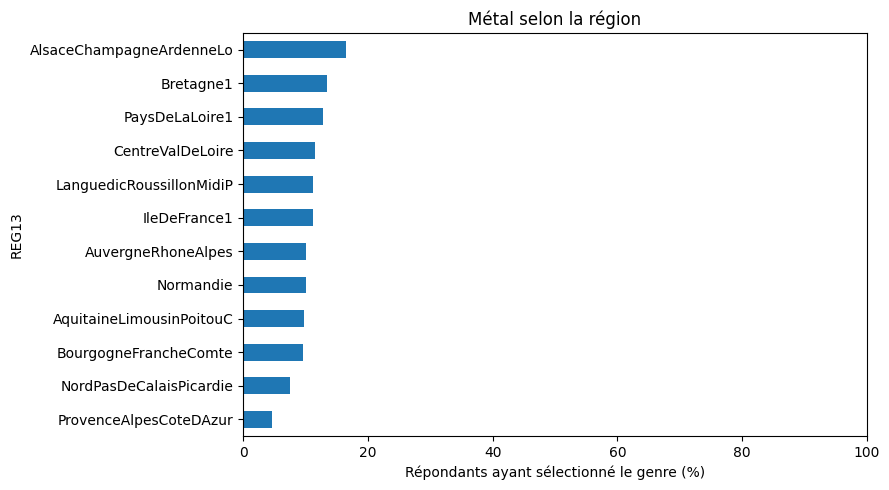

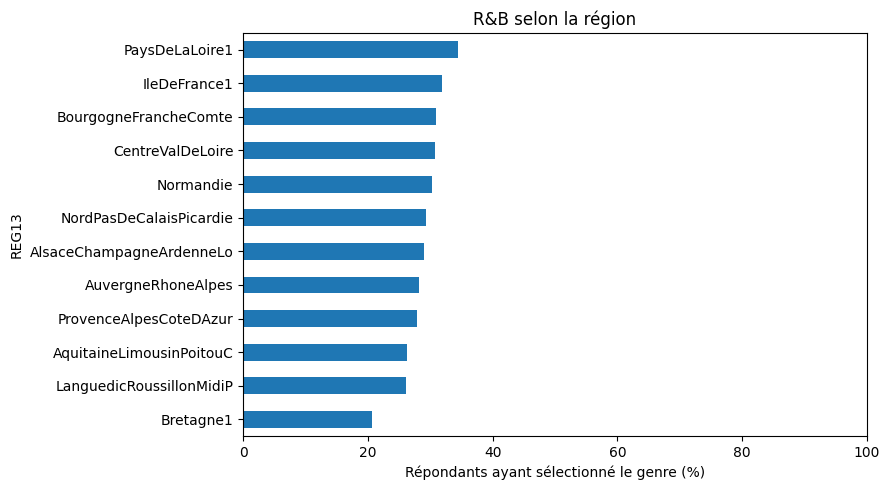

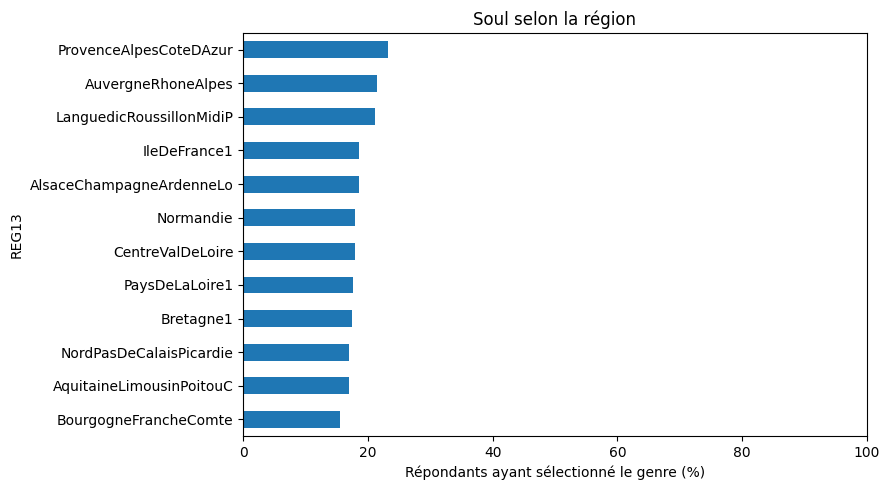

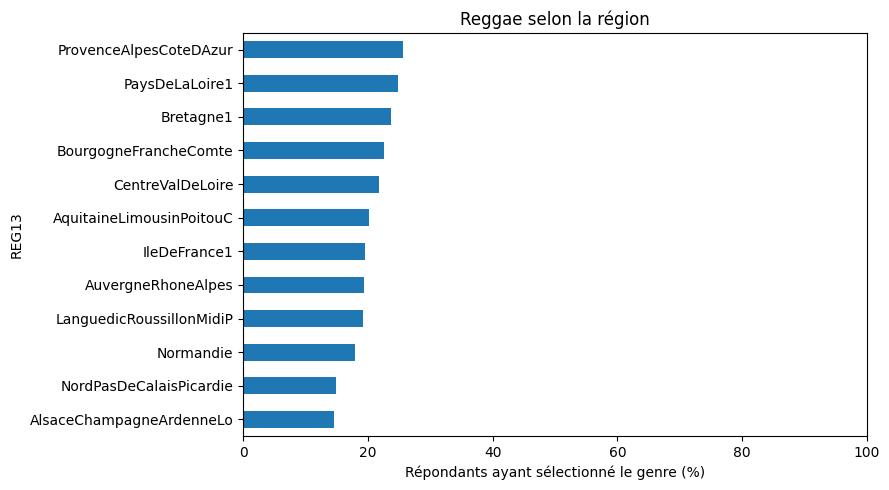

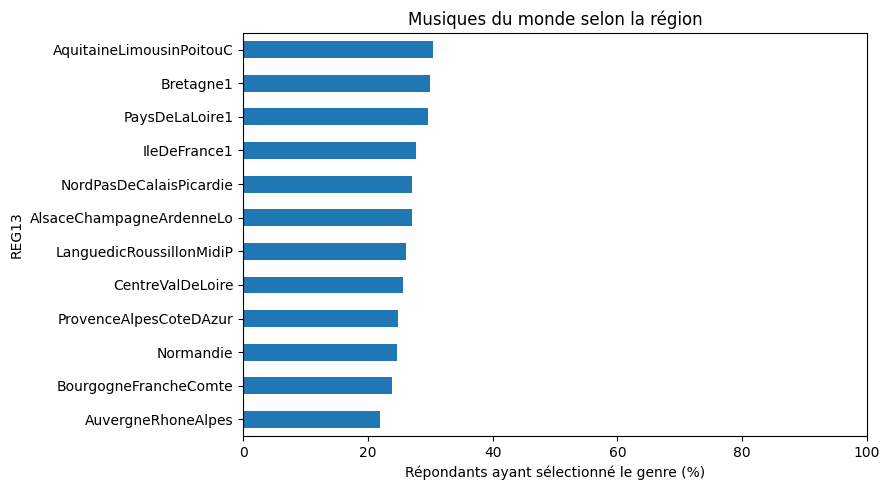

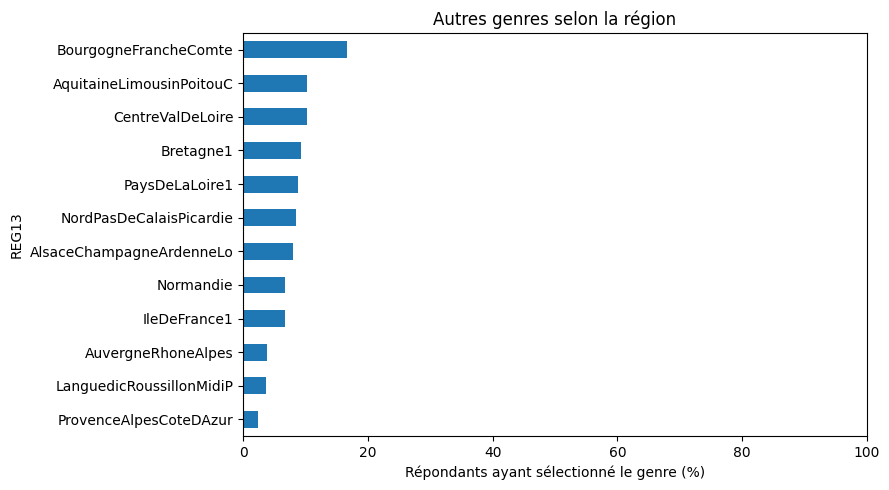

In [22]:
genres = [f"Q5_{i}" for i in range(1, 14)]

for colonne in genres:
    # Retrouver le nom du genre, en excluant les absences et les zéros
    valeurs = df[colonne].dropna()
    style = valeurs[valeurs.astype(str) != "0"].iloc[0]

    # Calculer les pourcentages par région
    repartition = pd.crosstab(
        df["REG13"],
        df[colonne],
        normalize="index"
    ) * 100

    # Afficher le pourcentage ayant sélectionné ce genre
    repartition[style].sort_values().plot.barh(figsize=(9, 5))

    plt.xlabel("Répondants ayant sélectionné le genre (%)")
    plt.title(f"{style} selon la région")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

# TEST 


In [23]:
regions = pd.DataFrame({
    "Effectif": df["REG13"].value_counts(),
    "Pourcentage (%)": (
        df["REG13"].value_counts(normalize=True) * 100
    ).round(1)
})

display(regions)

,Effectif,Pourcentage (%)
REG13,,
IleDeFrance1,441,20.0
AuvergneRhoneAlpes,271,12.3
AlsaceChampagneArdenneLo,220,10.0
AquitaineLimousinPoitouC,210,9.5
NordPasDeCalaisPicardie,205,9.3
LanguedicRoussillonMidiP,178,8.1
ProvenceAlpesCoteDAzur,143,6.5
PaysDeLaLoire1,139,6.3
Bretagne1,111,5.0
